# 01 · EDA and time split

Questions this notebook answers:

1. How do volume and fraud rate move week by week? (Only ~26 weeks of labels, so weeks, not months.)
2. How often do the same card holders reappear, and are their later transactions labelled fraud? (Vesta's entity-linked labels.)
3. How much does a random split inflate PR-AUC compared with a time split, and with a time split restricted to unseen entities? (Hypothesis H1 in `docs/hypotheses.md`.)

All logic lives in `src/fraud/`; this notebook only calls it.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from fraud.data import ENTITY_COL, TARGET, drop_seen_entities, load_dataset, random_split, time_split
from fraud.features import feature_columns
from fraud.train import fit_baseline, pr_auc

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
df = load_dataset("train")
print(f"{len(df):,} rows, {df.shape[1]} columns, {df.memory_usage(deep=True).sum() / 1e9:.2f} GB in memory")
print(f"fraud rate: {df[TARGET].mean():.4f}")
print(f"days {df['day'].min()}-{df['day'].max()}, {df['week'].nunique()} weeks")

590,540 rows, 439 columns, 0.99 GB in memory
fraud rate: 0.0350
days 1-182, 27 weeks


## 1. Volume and fraud rate over time

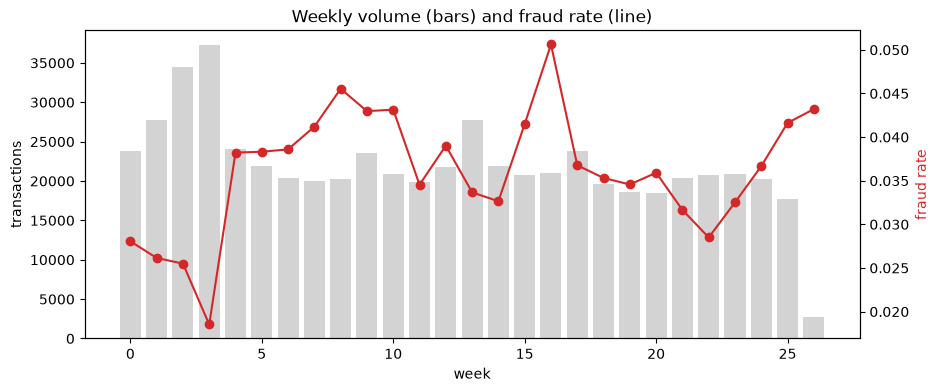

In [3]:
weekly = df.groupby("week").agg(n=(TARGET, "size"), fraud_rate=(TARGET, "mean"))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(weekly.index, weekly["n"], color="lightgray")
ax.set_xlabel("week")
ax.set_ylabel("transactions")
ax2 = ax.twinx()
ax2.plot(weekly.index, weekly["fraud_rate"], color="C3", marker="o")
ax2.set_ylabel("fraud rate", color="C3")
ax.set_title("Weekly volume (bars) and fraud rate (line)")
fig.savefig(FIG_DIR / "01_weekly_fraud_rate.png", dpi=120, bbox_inches="tight")

In [4]:
by_product = df.groupby("ProductCD", observed=True)[TARGET].agg(n="size", fraud_rate="mean")
by_amount = df.groupby(pd.qcut(df["TransactionAmt"], 10), observed=True)[TARGET].agg(n="size", fraud_rate="mean")
display(by_product, by_amount)

,n,fraud_rate
ProductCD,,
C,68519,0.116873
H,33024,0.047662
R,37699,0.037826
S,11628,0.058996
W,439670,0.020399


,n,fraud_rate
TransactionAmt,,
"(0.25, 25.95]",59511,0.055889
"(25.95, 35.95]",61650,0.032052
"(35.95, 49.0]",65116,0.032250
"(49.0, 57.95]",59647,0.019431
"(57.95, 68.769]",49346,0.028513
"(68.769, 100.0]",73349,0.036170
"(100.0, 117.0]",72079,0.019742
"(117.0, 159.95]",32399,0.043026
"(159.95, 275.293]",58390,0.038037


## 2. Label definition: do entities repeat across time?

`entity_key` = card1 + addr1 + card issue day. It approximates a card holder and is used **only** for this analysis, never as a feature.

In [5]:
time_train, time_test = time_split(df, test_size=0.2)

seen = time_test[ENTITY_COL].isin(time_train[ENTITY_COL].unique())
print(f"test rows whose entity appears in train: {seen.mean():.1%}")
display(time_test.groupby(seen.rename("entity_seen_in_train"))[TARGET].agg(n="size", fraud_rate="mean"))

fraud_entities = time_train.loc[time_train[TARGET] == 1, ENTITY_COL].unique()
had_fraud = time_test[ENTITY_COL].isin(fraud_entities)
print(f"test fraud rate, entities with fraud in train: {time_test.loc[had_fraud, TARGET].mean():.1%}")
print(f"test fraud rate, all other entities:           {time_test.loc[~had_fraud, TARGET].mean():.1%}")

test rows whose entity appears in train: 43.5%


,n,fraud_rate
entity_seen_in_train,,
False,66728,0.045543
True,51380,0.019949


test fraud rate, entities with fraud in train: 49.2%
test fraud rate, all other entities:           2.7%


## 3. Random vs time vs unseen-entity split

Same model, same features, three test sets. PR-AUC of a random model equals the test fraud rate, so the `lift` column is what to compare across rows.

In [6]:
features = feature_columns(df)

rand_train, rand_test = random_split(df, test_size=0.2, seed=0)
unseen_test = drop_seen_entities(time_train, time_test)

random_model = fit_baseline(rand_train, features)
time_model = fit_baseline(time_train, features)

evals = {
    "random": (random_model, rand_test),
    "time": (time_model, time_test),
    "time + unseen entities": (time_model, unseen_test),
}
results = pd.DataFrame([
    {"split": name, "n_test": len(test), "test_fraud_rate": test[TARGET].mean(), "pr_auc": pr_auc(model, test, features)}
    for name, (model, test) in evals.items()
]).set_index("split")
results["lift"] = results["pr_auc"] / results["test_fraud_rate"]
results.round(4)

,n_test,test_fraud_rate,pr_auc,lift
split,,,,
random,118174,0.0351,0.7659,21.7986
time,118108,0.0344,0.5672,16.4839
time + unseen entities,66728,0.0455,0.5603,12.3026


## Takeaways

- **A random split inflates performance.** PR-AUC 0.766 with a random split vs 0.567 split by time (lift over a random model 21.8 vs 16.5). Notebook 02 adds CIs: [0.751, 0.780] vs [0.537, 0.599].
- **Labels follow people.** Card holders with a fraud in the training period have a 49.2% fraud rate in later transactions, vs 2.7% for everyone else, which matches Vesta's label propagation.
- **New card holders are not simply "harder".** On test card holders unseen in training, PR-AUC is 0.560 (lift 12.3), but their fraud rate is also higher (4.6% vs 3.4%), so PR-AUC across the two groups is not directly comparable. Result recorded under H1 in `docs/hypotheses.md`.
- **Implication for M2:** split by time only, compute CIs by resampling card holders, and report seen vs new card holders separately.